# FWM tails with Gertler-style combs: EsT vs Ord

This notebook repeats the study of `FWM_tails.ipynb` with a different pair of correction combs. An X gate runs as
trained; then, in a **tail**, two pumps try to repair the photon losses the gate suffered. `FWM_tails.ipynb` used
Shirol's combs, which pass through the transmon's $|f\rangle$ level. Here the combs follow **Gertler et al. 2021**
(Eq. 4), which never leave the transmon's $\{g, e\}$ pair.

## Setup

**The code.** The odd kitten code of Shirol et al.: $|0_L\rangle = (|1\rangle + |5\rangle)/\sqrt2$ and
$|1_L\rangle = |3\rangle$, with 3 photons on average. Losing one photon turns them into
$(|0\rangle + \sqrt5|4\rangle)/\sqrt6$ and $|2\rangle$: the *error states* have an even photon number, 0, 2 or 4.

**The chip.** Shirol's Table I (`AQEC/device.py`), the same chip as `FWM_tails.ipynb`. As there, $\alpha$ and every
$\chi$ are stored positive with explicit minus signs, the higher-order terms (storage Kerr, $\chi'$) are on, and the
losses are the **decay set** (storage photon loss $\kappa_a$, readout decay $\kappa_r$, transmon $T_1$) unless stated
otherwise.

**The gates.** Two X gates of 1.1 μs, both trained in the closed system on this chip (`FWM_tails.ipynb` §3):

- **EsT:** error-semitransparent, so a loss during the gate stays repairable. Seed 24 of the $C_{\rm err}$ cost
  (`pulses/dgrape/u_X_est_err_closed_s24.npy`, picked in `est_gate_selection.ipynb`).
- **Ord:** the same training without the transparency terms (`pulses/dgrape/u_X_ord_closed.npy`).

The open-system gate d2 of `FWM_tails.ipynb` is not part of this study.

**Words and symbols.**

| term | meaning |
|---|---|
| tail | the time after the gate in which only the two combs act (cavity drive off) |
| comb T | the *transmon comb*: a plain transmon drive $\varepsilon_T(t)$ that excites $g \to e$ only on the error states |
| comb M | the *mixing comb*: a four-wave-mixing pump $\xi_M(t)$ that turns $|n,e,0\rangle$ into $|n{+}1,g,1\rangle$ |
| tooth $n$ | one frequency of a comb, tuned to photon number $n$ |
| $\xi_M$ cap | the largest pump strength allowed, 0.1 or 0.2 (dimensionless transmon displacement) |
| $\lvert 0\rangle$/$\lvert 1\rangle$ readout | readout empty / one readout photon. The fidelity *traces out* the readout |
| $F_{\rm pro}$ | process fidelity on the code against the ideal X. Gains in % are percentage points of $F_{\rm pro}$ |
| $F_{\rm tracked}$ | $F_{\rm pro}$ after the best free rotation of the cavity frame, $e^{i\theta\hat n}$ (§3.4); reported, never trained |
| Shirol tails | the tails of `FWM_tails.ipynb` (combs through $\lvert f\rangle$); shown as reference lines |
| $T_g$ | the end of the gate, 1.1 μs |
| $n_c$ | number of storage photon levels kept in the simulation |

In [1]:
import json
import os
import sys

if os.path.basename(os.path.abspath(".")) == "notebooks":   # the notebook lives in notebooks/; data paths are relative to the repo root
    os.chdir("..")
REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from AQEC import device as dev
from DGRAPE import fwm
from DGRAPE import fwm_tail as ft
from DGRAPE import fwm_tail_ge as ge
from DGRAPE.code import embedded_basis, process_targets

np.seterr(divide="ignore", over="ignore", invalid="ignore")

TWO_PI = 2 * np.pi
DT = ge.DT
GATES = ("EsT", "Ord")
GATE_COLOR = {"EsT": "#0072B2", "Ord": "#D55E00"}       # Okabe-Ito blue / vermilion, as FWM_tails.ipynb
CAP_MARK = {0.1: "o", 0.2: "s"}
RUN_DIR = os.path.join(os.path.expanduser("~"), "fwm_runs", "tailge")
PULSE_DIR = os.path.join("pulses", "dgrape")
os.makedirs("figures", exist_ok=True)


def tidy(ax, grid=True):
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def panel(ax, letter):
    ax.text(-0.02, 1.03, f"({letter})", transform=ax.transAxes, fontsize=11, fontweight="bold",
            ha="right", va="bottom")


def pct(x):
    return f"{100 * x:+.2f} %"

# 1. The idea

$$
|\psi_L\rangle \;\xrightarrow{\ \text{X gate, 1.1 μs}\ }\; \hat\rho(T_g)
\;\xrightarrow{\ \text{tail: combs T and M only}\ }\; \hat\rho(T_g + T_{\rm tail})
\quad\text{scored against}\quad X|\psi_L\rangle .
$$

**Gertler's two steps.** Gertler et al. (Eq. 4) correct the same kind of code with

$$
\hat H_d = \sum_{n\ \text{even}} \Big( \lambda_n\, |n,e,0\rangle\langle n,g,0| \;+\; \Omega_n\, |n{+}1,g,1\rangle\langle n,e,0| \Big) + \text{h.c.}
$$

1. **Comb T** excites the transmon, $g \to e$, but only when the photon number is even (an error state). This works
   because the transmon line moves by $\chi_{ge} = 1.12$ MHz per photon, so each photon number has its own tooth.
2. **Comb M** is a pump at $\omega_a + \omega_r - \omega_q$. Through the junction's four-wave mixing it turns
   $|n,e,0\rangle$ into $|n{+}1,g,1\rangle$: the lost photon comes back, a readout photon appears, and the transmon
   returns to $g$. The readout photon then leaks out ($1/\kappa_r = 0.27$ μs), so the repair cannot run backwards.

**What changes against the Shirol combs.** Shirol's comb 1 adds the photon and lifts the transmon to $|f\rangle$
($a^\dagger q^{\dagger 2}$); comb 2 hands the excitation to the readout ($q^2 r^\dagger$). Gertler's scheme never visits
$|f\rangle$:

- the transmon is a **qubit** $\{g, e\}$ in the tail: no anharmonicity, no $\chi_{ef}$, no $f \to e$ decay;
- a transmon decay during the repair ($e \to g$, $T_1 = 50$ μs) just undoes the repair, whereas $f \to e$ ($T_1 = 31$ μs)
  left a transmon stuck in $|e\rangle$;
- but the mixing coupling is **11 times weaker** per unit pump: $g_m = \sqrt{\chi_{ge}\chi_{qr}} = 2\pi\cdot 1.125$ MHz,
  against $\sqrt{\alpha\chi_{qr}} = 2\pi\cdot 12.3$ MHz for Shirol's comb 2. Shirol's combs borrow the large
  anharmonicity; Gertler's cannot.

Table 1 turns the coupling into time scales.

In [2]:
NUM = pd.DataFrame(ge.numbers_table((0.1, 0.14, 0.2, 0.3))).set_index("cap_M")
t1 = pd.DataFrame({
    "swap 0→1 (μs)": NUM["swap_us_0"], "swap 2→3 (μs)": NUM["swap_us_2"], "swap 4→5 (μs)": NUM["swap_us_4"],
    "rate 0→1 (kHz)": NUM["rate_kHz_0"], "Stark shift of the swap line (MHz)": NUM["stark_MHz"]})
t1.index.name = "ξ_M cap"
display(t1.style.format("{:.2f}").format({"rate 0→1 (kHz)": "{:.0f}"})
        .set_caption("Table 1. Time scales of the mixing comb on this chip"))
print(f"g_m = 2π·{ge.G_M / TWO_PI:.3f} MHz;  Shirol comb 2: 2π·{fwm.G2 / TWO_PI:.2f} MHz;  "
      f"selective transmon π pulse ≳ √3·π/χ_ge = {np.sqrt(3) * np.pi / dev.chi_ge:.2f} μs;  "
      f"photon loss of the code n̄κ_a = {100 * 3 * dev.kappa_a:.1f} %/μs")

,swap 0→1 (μs),swap 2→3 (μs),swap 4→5 (μs),rate 0→1 (kHz),Stark shift of the swap line (MHz)
ξ_M cap,,,,,
0.100000,2.222244,1.283013,0.993818,112,2.663100
0.140000,1.587317,0.916438,0.709870,157,5.219676
0.200000,1.111122,0.641507,0.496909,225,10.652400
0.300000,0.740748,0.427671,0.331273,337,23.967900


g_m = 2π·1.125 MHz;  Shirol comb 2: 2π·12.32 MHz;  selective transmon π pulse ≳ √3·π/χ_ge = 0.77 μs;  photon loss of the code n̄κ_a = 2.2 %/μs


**Table 1. Time scales of the mixing comb on this chip.**
*Symbols:* swap $n \to n{+}1$ = time for a full transfer $|n,e,0\rangle \to |n{+}1,g,1\rangle$ with one tooth at the cap,
$\pi/(2 g_m |\xi_M| \sqrt{n+1})$; rate = $g_m|\xi_M|$ in kHz; Stark shift = how far the pump moves that line,
$(2\alpha - \chi_{ge} - \chi_{qr})|\xi_M|^2$. The cap 0.14 row is where the Stark shift equals that of the Shirol campaign's cap.

**What it shows.** The repair is slow. At the old cap 0.1 the $0 \to 1$ path needs 2.2 μs, before the 0.8 μs a
photon-number-selective transmon flip needs. At 0.2 the swaps take 0.5–1.1 μs, but the pump then shifts the line by
10.7 MHz, ten times the 1.12 MHz spacing of the teeth. Meanwhile the code keeps losing photons at 2.2 % per μs. These
numbers set the grid we trained (decisions of 2026-11-03): caps **0.1 and 0.2**, tails of **1, 2 and 3 μs**.

# 2. Limits and fixed tones

## 2.1 The best an instant repair can do

The two ceilings of `FWM_tails.ipynb` §2.1 and §3, recomputed for both gates at $n_c = 24$ (the closed-trained gates
need it) with the readout cut to one level. They do not depend on which combs do the repair:

- **ideal repair** (`ft.ideal_repair_kraus`): every error state $|n,g\rangle$ ($n$ even) becomes $e^{i\phi_n}|n{+}1,g\rangle$,
  instantly at $T_g$, with the phases $\phi_n$ optimized;
- **best recovery** (`ft.optimal_recovery_fidelity`): the best quantum operation of any kind.

In [3]:
N_LIM = 24
B1 = embedded_basis(N_LIM, 1)
_, T1, W1 = process_targets("X", N_LIM, 1)
lim = []
for gate in GATES:
    for label, keep in [("closed", set()), ("photon loss only", {"a"}), ("all decay", None)]:
        R = ft.gate_output(ge.gate_pulse(gate), N_LIM, 1, keep)
        F0 = ft.fidelity_from_outputs(R, T1, W1)
        rep = ft.ideal_repair_fidelity(R, T1, W1, N_LIM, 1)
        opt = ft.optimal_recovery_fidelity(R, B1)
        lim.append({"gate": gate, "channels": label, "gate alone": F0, "+ ideal repair": rep["F"],
                    "+ best recovery": opt["F_opt"], "ideal-repair gain": rep["F"] - F0})
LIM = pd.DataFrame(lim).set_index(["gate", "channels"])
display(LIM.style.format("{:.5f}").format({"ideal-repair gain": "{:+.2%}"})
        .set_caption("Table 2. Fidelity limits at the end of each gate"))

**Table 2. Fidelity limits at the end of each gate.**
*Symbols:* every entry is $F_{\rm pro}$ at $T_g$ ($n_c = 24$, readout one level) except the last column,
(+ ideal repair) − (gate alone).

**What it shows.** A perfect, instant repair is worth +1.99 % after EsT (0.9671 → 0.9870) and +1.07 % after Ord
(0.9638 → 0.9745), because EsT keeps mid-gate losses repairable. Almost all of it is photon loss (closed rows: +0.00 %).
That is the most a tail could gain, and only if it took no time. A real tail also pays for its own length: the code
loses photons at 2.2 % per μs while the tail runs.

## 2.2 Fixed tones before training

Before training, `DGRAPE/fwm_tail_ge_prescan.py` scored three fixed tails after each gate
(`tables/fwm_tail_ge_prescan.csv`; forward only, $n_c = 16$ on $\{g, e\}$, the gate run at $n_c = 24$ and cut):

- **idle**: nothing on;
- **Gertler teeth**: Gertler's operating point moved to this chip. Every comb-M tooth gets the same swap rate $\Omega$,
  the teeth add up to the cap, $\lambda = (27/88)\,\Omega$ as Gertler ran, and the carriers include the mean Stark shift
  (`ge.gertler_amplitudes`);
- **sequential**: a selective π pulse on every error state in the first 0.8 μs, then the swap at full strength.

Each through the training's band filter and ramp ("chain") and raw.

,"EsT, 1 μs","EsT, 2 μs","EsT, 3 μs","Ord, 1 μs","Ord, 2 μs","Ord, 3 μs"
case,,,,,,
idle,-2.67 %,-6.30 %,-10.79 %,-2.64 %,-6.24 %,-10.69 %
"gertler, cap 0.1",-3.32 %,-8.69 %,-15.73 %,-3.28 %,-8.59 %,-15.56 %
"gertler, cap 0.15",-4.57 %,-13.07 %,-24.43 %,-4.52 %,-12.94 %,-24.20 %
"gertler, cap 0.2",-6.79 %,-20.86 %,-38.85 %,-6.71 %,-20.66 %,-38.51 %
"gertler, cap 0.3",-15.31 %,-46.22 %,-75.51 %,-15.12 %,-45.71 %,-75.07 %
"sequential, cap 0.1",-24.65 %,-24.24 %,-26.23 %,-24.36 %,-23.94 %,-25.91 %
"sequential, cap 0.15",-23.53 %,-24.11 %,-28.58 %,-23.22 %,-23.76 %,-28.17 %
"sequential, cap 0.2",-24.16 %,-24.32 %,-33.18 %,-23.83 %,-23.94 %,-32.74 %
"sequential, cap 0.3",-21.20 %,-30.94 %,-33.21 %,-20.82 %,-30.47 %,-32.78 %


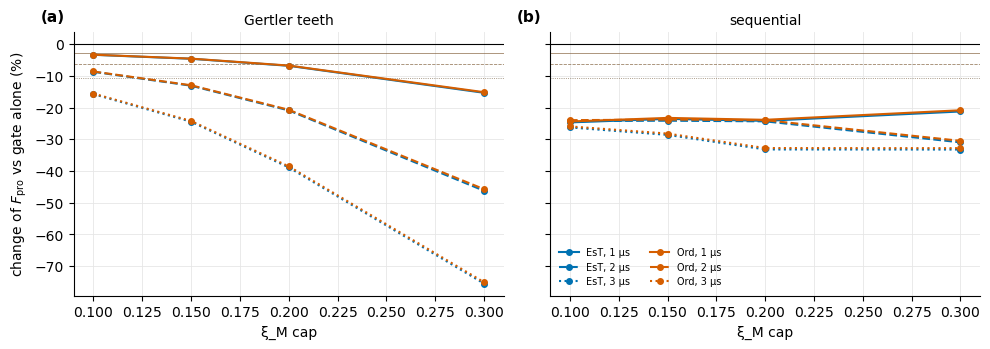

In [4]:
PRE = pd.read_csv("tables/fwm_tail_ge_prescan.csv")
pre = PRE[(PRE.kind == "chain") | (PRE.start == "idle")].copy()
pre["case"] = np.where(pre.start == "idle", "idle", pre.start + ", cap " + pre.cap_M.map("{:g}".format))
t3 = pre.pivot_table(index="case", columns=["gate", "tail_us"], values="gain")
t3 = t3.loc[["idle"] + [c for c in t3.index if c != "idle"]]
t3.columns = [f"{g}, {T:g} μs" for g, T in t3.columns]
display(t3.style.format(lambda v: pct(v)).set_caption("Table 3. Fixed tails: change against the gate alone"))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, start, letter in zip(axs, ("gertler", "sequential"), "ab"):
    for gate in GATES:
        for T, ls in zip((1.0, 2.0, 3.0), ("-", "--", ":")):
            d = PRE[(PRE.gate == gate) & (PRE.start == start) & (PRE.kind == "chain") & (PRE.tail_us == T)]
            ax.plot(d.cap_M, 100 * d.gain, ls, marker="o", ms=4, color=GATE_COLOR[gate],
                    label=f"{gate}, {T:g} μs")
            idle = PRE[(PRE.gate == gate) & (PRE.start == "idle") & (PRE.tail_us == T)].gain.iloc[0]
            ax.axhline(100 * idle, color=GATE_COLOR[gate], lw=0.6, ls=ls, alpha=0.5)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("ξ_M cap")
    ax.set_title({"gertler": "Gertler teeth", "sequential": "sequential"}[start], fontsize=10)
    tidy(ax)
    panel(ax, letter)
axs[0].set_ylabel("change of $F_{\\rm pro}$ vs gate alone (%)")
axs[1].legend(fontsize=7, ncol=2, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_tails_ge_prescan.png", dpi=150)
plt.show()

**Table 3 and Figure 1. Fixed tails: change against the gate alone.**
*Symbols:* change of $F_{\rm pro}$ in percentage points against the gate alone (EsT 0.96706, Ord 0.96380); lines =
the fixed tails through the training chain; thin horizontal lines = idle for the same gate and length (line style).

**What it shows.** No fixed tail beats doing nothing, and the stronger the pump the worse it gets.

- **Idle already costs 2.7 % per μs**: photon loss (2.2 %/μs) and the storage Kerr phase, which the tail would have to
  undo itself (no free rotation).
- **Gertler's teeth are too slow.** With photon loss as the only channel they still fall below idle at 1 μs
  (0.940 vs 0.948, cap 0.1, §2.3).
- **At cap 0.2 the Stark shift of the storage dominates** (§2.3).
- **The sequential start fails on selectivity.** Square π pulses also lift the code levels (n = 1, 3, 5): $P_e \approx 0.2$
  at the end, and comb M then pushes those out of the code.

The Shirol teeth also lost before training (`FWM_tails.ipynb` Table 8). The fixed tones only show what training must
fix.

## 2.3 Where the fixed teeth lose

The Gertler teeth after EsT, scored with parts of the model switched off.

In [5]:
def _dec(T, cap):
    b = np.zeros((ge.n_steps(T), 4)) if cap == 0 else ge.start_library(T, cap)["gertler"]
    row = {"tail (μs)": T, "case": "idle" if cap == 0 else f"Gertler, cap {cap:g}"}
    for name, kw in [("decay set", {}), ("Stark off", {"stark": False}), ("closed", {"keep": set()}),
                     ("closed, Stark off", {"keep": set(), "stark": False}), ("photon loss only", {"keep": {"a"}})]:
        row[name] = np.nan if (cap == 0 and "Stark" in name) else ge.score(b, "EsT", **kw)["F_pro"]
    return row

DEC = pd.DataFrame([_dec(T, c) for T in (1.0, 2.0) for c in (0, 0.1, 0.2)]).set_index(["tail (μs)", "case"])
alone = {name: ge.score(np.zeros((0, 4)), "EsT", **kw)["F_pro"]
         for name, kw in [("decay set", {}), ("closed", {"keep": set()}), ("photon loss only", {"keep": {"a"}})]}
display(DEC.style.format("{:.4f}", na_rep="").set_caption("Table 4. Gertler teeth after EsT, with parts switched off"))
print("EsT alone:", {k: round(v, 5) for k, v in alone.items()})

EsT alone: {'decay set': 0.96706, 'closed': 0.99869, 'photon loss only': 0.97467}


**Table 4. Gertler teeth after EsT, with parts switched off.**
*Symbols:* $F_{\rm pro}$ of EsT + tail. "Stark off" drops the pump's Stark term; "closed" drops every jump operator;
"photon loss only" keeps only $\kappa_a$, in the gate and the tail.

**What it shows.** At cap 0.2 and 2 μs the teeth lose 17 % even in the closed system, and switching the Stark term off
gives almost all of it back (0.808 → 0.956). The pump moves the storage frequency by $\chi_{ge}|\xi_M|^2$, which turns
the cavity by $\theta\hat n$. On this code that is a logical error: $|1\rangle$ and $|5\rangle$ drift apart by $4\theta$,
about 0.8 rad here. It is deterministic, like the Kerr phase, so an experiment could track it in its frame for free.
That is why we also report $F_{\rm tracked}$ (§3.4). Training must either cancel it or avoid it.

# 3. Method

## 3.1 Model and frame

`DGRAPE/fwm_tail_ge.py`. The gate runs on the full three-level model, as trained ($n_c = 24$, readout one level,
embedded with the readout empty). Its output is cut to $n_c = 16$ and projected onto the transmon's $\{g, e\}$; the
projection drops at most $10^{-5}$ of the trace (Ord; $2\cdot10^{-7}$ for EsT). The tail then runs on storage
× $\{g, e\}$ × readout (2 levels), $d = 64$ against 96, in DGRAPE's frame (rotating at the linear mode frequencies):

$$
\hat H(t) = \hat H_d + \varepsilon_T(t)\,\hat q^\dagger + g_m\,\xi_M(t)\,\hat a^\dagger \hat r^\dagger \hat q + \text{h.c.}
\;-\; |\xi_M(t)|^2\,\hat S,\qquad \hat S = 2\alpha\,\hat q^\dagger\hat q + \chi_{ge}\hat n_a + \chi_{qr}\hat n_r .
$$

$\hat H_d$ is DGRAPE's drift restricted to $\{g, e\}$ ($-\chi_{ge}|e\rangle\langle e|\hat n_a - \chi_{qr}|e\rangle\langle e|\hat n_r$ plus
Kerr and $\chi'$). The Stark term $\hat S$ is `fwm.py`'s. Its $2\alpha$ part comes from $|f\rangle$ in a real
transmon, so on two levels it has to be put in by hand. Both combs sit within a few MHz of zero in this frame (comb T
teeth at $+n\chi_{ge}$, comb M at $-n\chi_{ge}$ in the $e^{i\Delta t}$ convention), and the controls are constant over each 2 ns step, so
**one exponential per step is exact** (`fwm.propagate`, midpoint, one sub-step, one tone with zero carrier).
Gradients are `fwm.fidelity_and_grad(..., want_u=True)`, exact for the propagator.

## 3.2 Controls and cost

One complex waveform per comb, $b(t) = (\varepsilon_T^I, \varepsilon_T^Q, \xi_M^I, \xi_M^Q)$, from a pre-image $x$ through
the band filter (±12 MHz on both) and the 48 ns ramp, each comb scaled so both share the box $|x| \le 25$.

$$
C = 1 - F_{\rm pro} + 8\cdot10^{-5}\sum_{t,c} s_c^2\,(|b_c(t)| - \text{cap}_c)_+^2 + 10^{-5}\sum_{t,c} s_c^2\,|b_c(t{+}dt) - b_c(t)|^2,
\qquad s_c = 25/\text{cap}_c ,
$$

the balance of `FWM_tails.ipynb`. Caps: $|\varepsilon_T| \le 2\pi\cdot 1$ MHz (keeps the leak to the dropped $|f\rangle$ near
$(2\varepsilon_T/\alpha)^2 \approx 2\cdot10^{-4}$; checked in §6), $|\xi_M| \le$ 0.1 or 0.2. $F_{\rm pro}$ traces the readout
out, as before, and there is **no free rotation**. L-BFGS-B, 600 iterations, gtol $10^{-12}$, best-vs-final.

## 3.3 The grid

EsT and Ord × tail 1, 2, 3 μs × cap 0.1, 0.2 × two starts, **gertler** (§2.2) and **zero** (small noise, 5 % of
each cap, seed 1) = 24 runs (`DGRAPE/fwm_tail_ge_grid.py`). The better start per configuration is the result.

## 3.4 Frame tracking (reported, not trained)

$F_{\rm tracked} = \max_\theta F_{\rm pro}\big(e^{i\theta\hat n_a}\,\hat\rho\,e^{-i\theta\hat n_a}\big)$: the best free
cavity-frame update (`ge.frame_tracked_fidelity`). It removes the deterministic storage rotation from the Stark shift
and the linear part of the Kerr phase. This is the same idea as the Kerr decoding of `FWM_tails.ipynb` §8 (Gertler,
Methods). Gains in $F_{\rm tracked}$ are always against a reference that is also tracked: the gate alone, or the gate
+ an idle tail of the same length (decision of 2026-11-03). The second one matters most: a tracked idle tail is the
fair "do nothing" for a tail that is allowed to fix the frame.

## 3.5 Checks

`validation/test_fwm_tail_ge.py` (12 tests, ~10 s) covers the following:
- the exact gradient against an augmented-generator derivative and finite differences, on two and three levels;
- idle on two levels against three levels projected;
- weak combs on two vs three levels (agree to $2\cdot10^{-4}$);
- the full swap at $\pi/(2g_m|\xi_M|\sqrt{n+1})$;
- the tooth carriers and Gertler's amplitudes;
- the objective's pre-image gradient, and 3 jobs against 1;
- the gate alone projected against three levels;
- frame tracking undoing a known rotation.

Appendix A shows two of them live.

# 4. Training as run

In [6]:
def tag_of(gate, T, cap, s):
    return f"X_tailge_{gate.lower()}_T{T:g}_c{int(round(100 * cap))}_{s}"


def load_run(tag):
    for d in (PULSE_DIR, RUN_DIR):
        p = os.path.join(d, f"{tag}.json")
        if os.path.exists(p):
            with open(p) as f:
                return json.load(f), np.load(os.path.join(d, f"b4_{tag}.npy"))
    return None, None


RUNS = []
HIST = {}
for gate in GATES:
    for T in ge.TAIL_US_GRID:
        for cap in ge.CAP_M_GRID:
            for s in ("g", "z"):
                tag = tag_of(gate, T, cap, s)
                info, b4 = load_run(tag)
                if info is None:
                    continue
                HIST[tag] = pd.DataFrame(info["history"])
                RUNS.append({"tag": tag, "gate": gate, "tail (μs)": T, "cap": cap,
                             "start": {"g": "gertler", "z": "zero"}[s], "F start": info["F_pro_start"],
                             "F trained": info["F_pro"], "iterations": info["nit"], "hours": info["wall_s"] / 3600,
                             "max |ε_T| (MHz)": info["max_eps_T_MHz"], "max |ξ_M|": info["max_xi_M"],
                             "pinned": info["frac_preimage_pinned"], "returned": info["returned"]})
RUNS = pd.DataFrame(RUNS)
print(f"{len(RUNS)} of 24 runs on disk")
display(RUNS.set_index("tag").style.format({"F start": "{:.4f}", "F trained": "{:.5f}", "hours": "{:.1f}",
                                            "max |ε_T| (MHz)": "{:.3f}", "max |ξ_M|": "{:.3f}", "pinned": "{:.2%}"})
        .set_caption("Table 5. The training runs"))

24 of 24 runs on disk


,gate,tail (μs),cap,start,F start,F trained,iterations,hours,max |ε_T| (MHz),max |ξ_M|,pinned,returned
tag,,,,,,,,,,,,
X_tailge_est_T1_c10_g,EsT,1.000000,0.100000,gertler,0.9339,0.94571,600,2.0,0.274,0.001,0.00%,best_seen
X_tailge_est_T1_c10_z,EsT,1.000000,0.100000,zero,0.9400,0.94571,575,1.9,0.274,0.000,0.00%,best_seen
X_tailge_est_T1_c20_g,EsT,1.000000,0.200000,gertler,0.8992,0.94570,600,2.2,0.275,0.002,0.00%,best_seen
X_tailge_est_T1_c20_z,EsT,1.000000,0.200000,zero,0.9400,0.94571,459,1.6,0.272,0.001,0.00%,best_seen
X_tailge_est_T2_c10_g,EsT,2.000000,0.100000,gertler,0.8802,0.92501,600,4.0,0.295,0.007,0.00%,best_seen
X_tailge_est_T2_c10_z,EsT,2.000000,0.100000,zero,0.9035,0.92500,600,4.1,0.300,0.000,0.00%,final
X_tailge_est_T2_c20_g,EsT,2.000000,0.200000,gertler,0.7584,0.93311,600,5.0,0.719,0.170,0.00%,final
X_tailge_est_T2_c20_z,EsT,2.000000,0.200000,zero,0.9035,0.92964,600,4.3,0.681,0.106,0.00%,best_seen
X_tailge_est_T3_c10_g,EsT,3.000000,0.100000,gertler,0.8097,0.91246,600,6.3,0.565,0.075,0.00%,final


**Table 5. The training runs.**
*Symbols:* F start / F trained = training $F_{\rm pro}$ ($n_c = 16$, $\{g, e\}$, decay set) of the start and of the returned
pulse; hours = wall time with 8 runs side by side on the 16-core PC; pinned = share of the pre-image at the box;
returned = which pulse the run kept (best seen during the run, or the final iterate).

**What it shows.** All 24 runs finished (12.9 h for the grid), none pinned at the box.

- **At 1 μs the mixing comb stays off** ($|\xi_M| \le 0.002$ at both caps), and both starts end at the same $F_{\rm pro}$
  to $10^{-5}$. Only the transmon comb is used, at 0.27 MHz. All four 1 μs zero starts stopped on their own before 600
  iterations.
- **At 2 μs the mixing comb turns on only at cap 0.2** ($|\xi_M|$ 0.11–0.17); at cap 0.1 it stays off.
- **At 3 μs it turns on at both caps** from the gertler start (0.07–0.12), and at cap 0.2 from both starts.

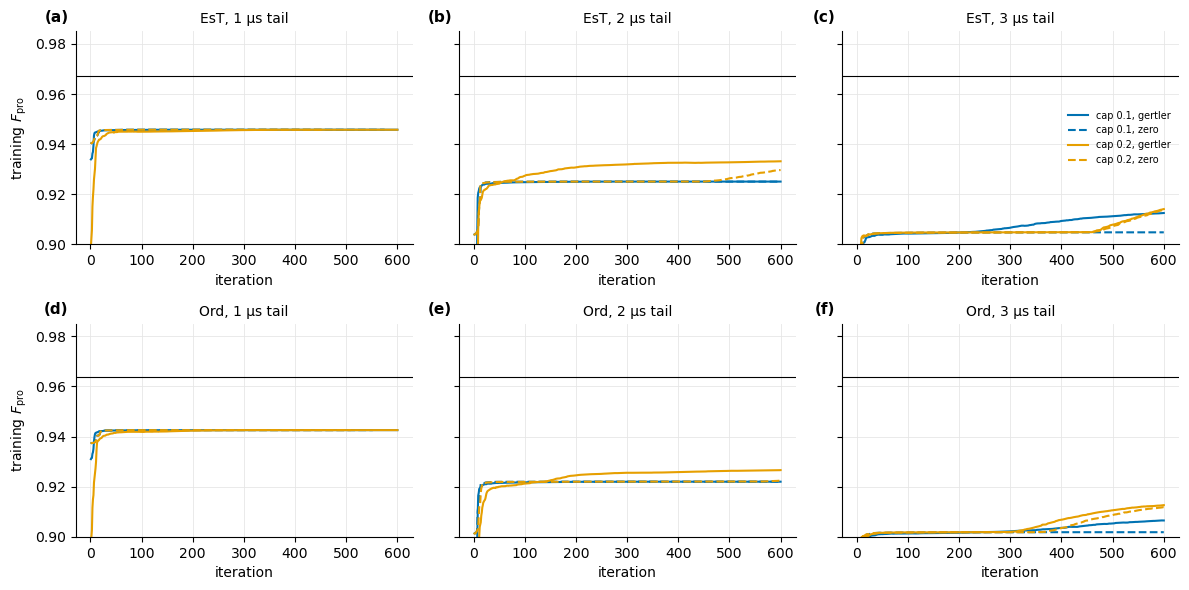

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharey="row")
for i, gate in enumerate(GATES):
    for j, T in enumerate(ge.TAIL_US_GRID):
        ax = axs[i, j]
        for cap in ge.CAP_M_GRID:
            for s, ls in (("g", "-"), ("z", "--")):
                tag = tag_of(gate, T, cap, s)
                if tag in HIST:
                    h = HIST[tag]
                    ax.plot(h["it"], h["F_pro"], ls, color="#0072B2" if cap == 0.1 else "#E69F00",
                            label=f"cap {cap:g}, {'gertler' if s == 'g' else 'zero'}")
        F0 = ge.score(np.zeros((0, 4)), gate)["F_pro"]
        ax.axhline(F0, color="k", lw=0.8)
        ax.set_title(f"{gate}, {T:g} μs tail", fontsize=10)
        ax.set_xlabel("iteration")
        tidy(ax)
        panel(ax, "abcdef"[3 * i + j])
    axs[i, 0].set_ylabel("training $F_{\\rm pro}$")
axs[0, 2].legend(fontsize=7, frameon=False)
for ax in axs.ravel():
    ax.set_ylim(0.90, 0.985)
fig.tight_layout()
fig.savefig("figures/fwm_tails_ge_training.png", dpi=150)
plt.show()

**Figure 2. Training curves.**
*Symbols:* training $F_{\rm pro}$ per L-BFGS-B iteration; color = cap (blue 0.1, orange 0.2), solid = gertler start,
dashed = zero start; black line = the gate alone.

**What it shows.** Every run jumps within ~20 iterations to a plateau set by the transmon comb alone (it cancels the
cavity rotation, §5.2). A run that turns the mixing comb on leaves that plateau slowly, over hundreds of iterations. At
3 μs those runs are still climbing at 600 iterations, so they are not converged. But they sit 5 % below the gate
alone, far more than further training could recover at that rate.

# 5. Results

Held-out scores from `DGRAPE/fwm_tail_ge_score.py` (`tables/fwm_tail_ge_heldout.csv`). The go / no-go number is
the gain at $n_c = 28$ (gate and tail both there, no cut), against the gate alone in the same condition. The bar is
**+0.3 %**, as in `FWM_tails.ipynb`.

In [8]:
HO = pd.read_csv("tables/fwm_tail_ge_heldout.csv")
tr = HO[HO.kind == "trained"]
best = (tr[tr.condition == "train"].sort_values("F_pro").groupby(["gate", "tail_us", "cap_M"]).tail(1)
        [["gate", "tail_us", "cap_M", "tag", "start"]])
res = []
for _, b in best.iterrows():
    r = {"gate": b.gate, "tail (μs)": b.tail_us, "cap": b.cap_M, "start": b.start}
    for cond, lab in (("train", "n_c 16"), ("nc28", "n_c 28")):
        row = tr[(tr.tag == b.tag) & (tr.condition == cond)].iloc[0]
        r[f"F ({lab})"] = row.F_pro
        r[f"gain ({lab})"] = row.gain_vs_alone
    r28 = tr[(tr.tag == b.tag) & (tr.condition == "nc28")].iloc[0]
    r["gain tracked (n_c 28)"] = r28.gain_vs_alone_tracked
    r["vs idle (n_c 28)"] = r28.gain_vs_idle
    r["vs idle, tracked (n_c 28)"] = r28.gain_vs_idle_tracked
    r["go"] = "GO" if r["gain (n_c 28)"] >= 0.003 else "no"
    res.append(r)
RES = pd.DataFrame(res).sort_values(["gate", "tail (μs)", "cap"]).set_index(["gate", "tail (μs)", "cap"])
fmt = {c: "{:.5f}" for c in RES.columns if c.startswith("F (")}
fmt.update({c: pct for c in RES.columns if "gain" in c or "vs idle" in c})
display(RES.style.format(fmt).set_caption("Table 6. Trained tails: the better start per gate, length and cap"))
print("Shirol tails (FWM_tails.ipynb §6, n_c 28):",
      {g: f"{pct(v['gain'])} at {v['tail_us']} μs" for g, v in ge.SHIROL_BEST.items()})

Shirol tails (FWM_tails.ipynb §6, n_c 28): {'EsT': '+0.32 % at 0.8 μs', 'Ord': '-0.58 % at 1.0 μs'}


**Table 6. Trained tails: the better start per gate, length and cap.**
*Symbols:* F = $F_{\rm pro}$ of gate + tail; gain = change against the gate alone in the same condition (n_c 16 = training
condition, n_c 28 = held out, no cut); gain tracked = the same for $F_{\rm tracked}$ against the tracked gate alone
(§3.4); vs idle = against the gate + a zero tail of the same length; vs idle, tracked = $F_{\rm tracked}$ against the
tracked idle tail; go = gain at $n_c$ 28 ≥ +0.3 %.

**What it shows.** **No go.** Every tail scores below its gate alone, by 2.1 % at 1 μs, 3.4–4.2 % at 2 μs and
5.1–5.7 % at 3 μs. The held-out $n_c = 28$ agrees with training to $10^{-5}$.

- **The best number belongs to the shortest tail**, −2.1 % at 1 μs, because a tail that does nothing loses least.
- **Frame tracking does not change the verdict.** "gain tracked" equals "gain": the trained tails already undo the
  cavity rotation with the transmon comb, so a free frame update has nothing left to fix.
- **Against idle the tails look good (+0.5 to +5.6 %), but most of that is the same rotation.** Against a *tracked* idle
  tail, the 1 μs tails gain nothing (+0.00 %), and the 2 μs cap 0.1 tails +0.1 %. Only tails that use the mixing comb
  gain more: +0.6–0.9 % at 2 μs, cap 0.2, and +0.7–1.4 % at 3 μs. §5.2 asks whether that part is repair.
- **EsT and Ord are the same** within a third of a percent at every length, measured against their own gates.

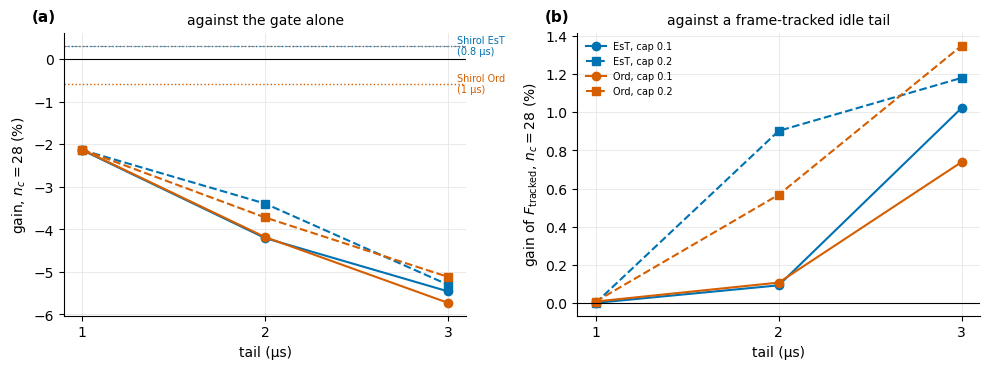

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, title, letter in zip(axs, ("gain (n_c 28)", "vs idle, tracked (n_c 28)"),
                                  ("against the gate alone", "against a frame-tracked idle tail"), "ab"):
    for gate in GATES:
        for cap in ge.CAP_M_GRID:
            d = RES.xs(gate, level="gate").xs(cap, level="cap")
            ax.plot(d.index, 100 * d[col], marker=CAP_MARK[cap], color=GATE_COLOR[gate],
                    ls="-" if cap == 0.1 else "--", label=f"{gate}, cap {cap:g}")
        if letter == "a":
            s = ge.SHIROL_BEST[gate]
            ax.axhline(100 * s["gain"], color=GATE_COLOR[gate], lw=1, ls=":")
            ax.text(3.05, 100 * s["gain"], f"Shirol {gate}\n({s['tail_us']:g} μs)", color=GATE_COLOR[gate],
                    fontsize=7, va="center")
    ax.axhline(0, color="k", lw=0.8)
    if letter == "a":
        ax.axhline(30 / 100, color="0.5", lw=0.6, ls="-.")
    ax.set_xlabel("tail (μs)")
    ax.set_xticks(ge.TAIL_US_GRID)
    ax.set_title(title, fontsize=10)
    tidy(ax)
    panel(ax, letter)
axs[0].set_ylabel("gain, $n_c = 28$ (%)")
axs[1].set_ylabel("gain of $F_{\\rm tracked}$, $n_c = 28$ (%)")
axs[1].legend(fontsize=7, frameon=False)
fig.subplots_adjust(wspace=0.35)
fig.tight_layout()
fig.savefig("figures/fwm_tails_ge_main.png", dpi=150)
plt.show()

**Figure 3. Gain of the trained tails, held out at $n_c = 28$.**
*Symbols:* (a) $F_{\rm pro}$ against the gate alone; dotted lines = the best Shirol tail per gate (`FWM_tails.ipynb`
§6, no free rotation, at the length given); dash-dot gray = the +0.3 % bar. (b) $F_{\rm tracked}$ against the gate + an idle
tail of the same length, also tracked: what the combs add beyond a free frame update. Color = gate (blue EsT,
vermilion Ord); markers / line style = cap (circle solid 0.1, square dashed 0.2).

**What it shows.** (a) Every point is far below zero and below both Shirol lines, and the loss grows by about 1.6 % per
μs. (b) What the combs add on top of a free frame update grows with length and cap, but stays at or below +1.4 %.
That is less than the 2.2 % per μs the tail costs in photon loss.

## 5.2 Is any of it repair?

The extra over a tracked idle tail (last column of Table 6), split by loss channel. Both the tail and the idle reference
are scored with the same channels in the gate and the tail.

In [10]:
rep = []
for b in best.itertuples():
    r = {"gate": b.gate, "tail (μs)": b.tail_us, "cap": b.cap_M}
    for cond, lab in (("train", "decay set"), ("closed", "closed"), ("loss_only", "photon loss only"),
                      ("no_loss", "all but photon loss")):
        row = tr[(tr.tag == b.tag) & (tr.condition == cond)].iloc[0]
        r[lab] = row.gain_vs_idle_tracked
        if cond == "loss_only":
            r["readout photons (loss only)"] = row.n_r_end
    rep.append(r)
REP = pd.DataFrame(rep).sort_values(["gate", "tail (μs)", "cap"]).set_index(["gate", "tail (μs)", "cap"])
display(REP.style.format({c: ("{:.4f}" if c.startswith("readout") else pct) for c in REP.columns})
        .set_caption("Table 7. Extra over a frame-tracked idle tail, by loss channel"))

**Table 7. Extra over a frame-tracked idle tail, by loss channel.**
*Symbols:* each entry is $F_{\rm tracked}$(gate + trained tail) − $F_{\rm tracked}$(gate + idle tail of the same length),
both scored with the channels named (in the gate and the tail; training condition otherwise); readout photons =
$\langle\hat n_r\rangle$ left at the end of the tail with photon loss only, the trace of completed repairs that have not yet
leaked out.

**What it shows.** Where the mixing comb is on (2 μs at cap 0.2, 3 μs), the tails **do repair**. Most of the extra
comes with photon loss (+1.0–2.3 % with photon loss only), and readout photons appear (0.01–0.03). In the closed system
and with the other channels the extra is only the 0.0–0.4 % that tails without the mixing comb also get: that part is
coherent, the transmon comb correcting phases beyond a single frame rotation. The repairs are slow. Even the best, Ord
at 3 μs, cap 0.2, wins back +2.3 % with photon loss only, against the 6.5 % that 3 μs of tracked idling costs.

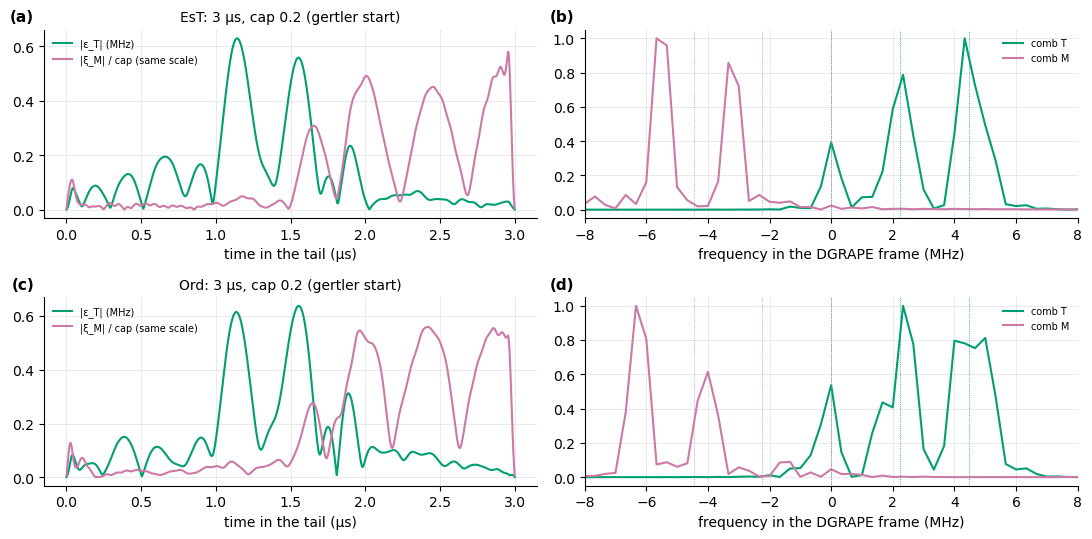

In [11]:
def waveforms(tag):
    info, b4 = load_run(tag)
    eps, xi = ge.eps_xi(b4)
    return info, eps, xi

# the tail that repairs most per gate (largest extra over a tracked idle tail), not the least bad one
top = {g: RES.xs(g, level="gate")["vs idle, tracked (n_c 28)"].idxmax() for g in GATES}
fig, axs = plt.subplots(2, 2, figsize=(11, 5.5))
for i, gate in enumerate(GATES):
    T, cap = top[gate]
    tag = best[(best.gate == gate) & (best.tail_us == T) & (best.cap_M == cap)].tag.iloc[0]
    info, eps, xi = waveforms(tag)
    t = (np.arange(len(eps)) + 0.5) * DT
    ax = axs[i, 0]
    ax.plot(t, np.abs(eps) / TWO_PI, color="#009E73", label="|ε_T| (MHz)")
    ax.plot(t, np.abs(xi) / cap * (ge.CAP_T / TWO_PI), color="#CC79A7", label="|ξ_M| / cap (same scale)")
    ax.set_xlabel("time in the tail (μs)")
    ax.set_title(f"{gate}: {T:g} μs, cap {cap:g} ({info['start']} start)", fontsize=10)
    ax.legend(fontsize=7, frameon=False)
    tidy(ax)
    panel(ax, "ac"[i])
    ax = axs[i, 1]
    f = np.fft.fftshift(np.fft.fftfreq(len(eps), DT))
    for sig, c, lab in ((eps, "#009E73", "comb T"), (xi, "#CC79A7", "comb M")):
        S = np.abs(np.fft.fftshift(np.fft.fft(sig))) ** 2
        ax.plot(f, S / S.max(), color=c, label=lab)
    fr = ge.tooth_frequencies(0.0)
    for k, n in enumerate(ge.ERROR_FOCK):
        # numpy's fft puts a tone exp(+i Delta t) at +Delta/2pi
        ax.axvline(fr["T"][k] / TWO_PI, color="#009E73", lw=0.6, ls=":")
        ax.axvline(fr["M"][k] / TWO_PI, color="#CC79A7", lw=0.6, ls=":")
    ax.set_xlim(-8, 8)
    ax.set_xlabel("frequency in the DGRAPE frame (MHz)")
    ax.legend(fontsize=7, frameon=False)
    tidy(ax)
    panel(ax, "bd"[i])
fig.tight_layout()
fig.savefig("figures/fwm_tails_ge_waveforms.png", dpi=150)
plt.show()

**Figure 4. The tail that repairs most, per gate** (largest extra over a tracked idle tail, Table 6).
*Symbols:* (a, c) moduli of the two comb waveforms over the tail: $|\varepsilon_T|$ in MHz and $|\xi_M|$ scaled so its cap
sits at the comb-T cap (1 MHz); (b, d) power spectra, each normalized to its peak; dotted lines = the bare tooth
frequencies on the error states $n = 0, 2, 4$, without Stark shift (green comb T at $+n\chi_{ge}$, pink comb M at
$-n\chi_{ge}$; a tooth $e^{i\Delta t}$ appears at $+\Delta/2\pi$).

**What it shows.** Both gates get the same plan, in two steps like Gertler's, and placed late as in the Shirol tails.

- **Comb T** works mostly between 1.0 and 1.6 μs. Its power sits on the error-state teeth: 0, +2.2 and +4.5 MHz.
- **Comb M** then rises and stays near the cap to the end.
- **Comb M drives the $2 \to 3$ and $4 \to 5$ paths, 1.1 MHz (EsT) to 1.8 MHz (Ord) below their bare teeth.** That
  offset is the pump's own Stark shift. It puts almost nothing on the $0 \to 1$ tooth, the slowest path (2.2 μs at cap 0.1), which carries only 1/6
  of the $|0_L\rangle$ error state.
- **The first microsecond is nearly idle,** with a weak comb T that corrects phases.

A loss after comb T has finished (about 1.6 μs into the tail) is not flipped to $e$, so comb M cannot repair it. That
is the same "late shot" floor as in `FWM_tails.ipynb` §6.2, but the shot here lasts about 2 μs, not 0.6 μs.

# 6. Robustness and what the two-level model hides

Each best tail scored under conditions it was not trained on, gains against the gate alone in the same condition.

In [12]:
COND = ["train", "nc28", "three_level", "nr3", "all_ch", "g/sqrt2", "pump_x0.9", "pump_x1.1", "stark_off",
        "closed", "loss_only", "no_loss"]
rob = tr[tr.tag.isin(best.tag)].pivot_table(index="condition", columns="tag", values="gain_vs_alone").reindex(COND)
lab = {r.tag: f"{r.gate} {r.tail_us:g} μs c{r.cap_M:g}" for r in best.itertuples()}
rob = rob[[t for t in best.sort_values(["gate", "tail_us", "cap_M"]).tag]].rename(columns=lab)
display(rob.style.format(pct).set_caption("Table 8. Gain against the gate alone under held-out conditions"))

tag,EsT 1 μs c0.1,EsT 1 μs c0.2,EsT 2 μs c0.1,EsT 2 μs c0.2,EsT 3 μs c0.1,EsT 3 μs c0.2,Ord 1 μs c0.1,Ord 1 μs c0.2,Ord 2 μs c0.1,Ord 2 μs c0.2,Ord 3 μs c0.1,Ord 3 μs c0.2
condition,,,,,,,,,,,,
train,-2.14 %,-2.14 %,-4.21 %,-3.39 %,-5.46 %,-5.30 %,-2.12 %,-2.12 %,-4.18 %,-3.72 %,-5.73 %,-5.12 %
nc28,-2.14 %,-2.14 %,-4.21 %,-3.39 %,-5.46 %,-5.30 %,-2.12 %,-2.12 %,-4.18 %,-3.72 %,-5.73 %,-5.12 %
three_level,-2.14 %,-2.14 %,-4.21 %,-3.40 %,-5.46 %,-5.30 %,-2.12 %,-2.12 %,-4.18 %,-3.72 %,-5.73 %,-5.12 %
nr3,-2.14 %,-2.14 %,-4.21 %,-3.39 %,-5.46 %,-5.30 %,-2.12 %,-2.12 %,-4.18 %,-3.72 %,-5.73 %,-5.12 %
all_ch,-2.41 %,-2.41 %,-4.71 %,-3.96 %,-6.25 %,-6.09 %,-2.38 %,-2.38 %,-4.66 %,-4.23 %,-6.45 %,-5.85 %
g/sqrt2,-2.14 %,-2.14 %,-4.21 %,-3.80 %,-5.85 %,-5.75 %,-2.12 %,-2.12 %,-4.18 %,-3.97 %,-5.97 %,-5.63 %
pump_x0.9,-2.16 %,-2.16 %,-4.28 %,-8.48 %,-5.85 %,-5.69 %,-2.14 %,-2.14 %,-4.26 %,-5.75 %,-6.00 %,-5.79 %
pump_x1.1,-2.15 %,-2.15 %,-4.28 %,-10.48 %,-5.83 %,-5.63 %,-2.14 %,-2.14 %,-4.26 %,-9.05 %,-5.95 %,-5.92 %
stark_off,-2.14 %,-2.14 %,-4.21 %,-50.20 %,-10.16 %,-11.06 %,-2.12 %,-2.12 %,-4.18 %,-47.05 %,-7.40 %,-13.54 %


**Table 8. Gain against the gate alone under held-out conditions.**
*Symbols:* train = training condition ($n_c$ 16, $\{g, e\}$, gate at 24 cut); nc28 = gate and tail at $n_c = 28$;
three_level = the same tail on the three-level transmon ($|f\rangle$, $\alpha$, $\chi_{ef}$, $T_1^{ef}$ back in); nr3 = three
readout levels; all_ch = dephasing and heating on; g/√2 = the other coupling convention; pump_x0.9 / x1.1 = both combs
miscalibrated by ∓10 %; stark_off = no pump Stark term; closed / loss_only / no_loss = no jumps / storage photon loss
only / everything but photon loss, in the gate and the tail.

**What it shows.**

- **The two-level model is safe.** With $|f\rangle$, $\alpha$, $\chi_{ef}$ and $T_1^{ef}$ back in, every gain moves by at
  most 0.01 %. So do a second readout photon and $n_c = 28$.
- **The extra channels cost a little more:** dephasing and heating take 0.3–0.8 % more, growing with the tail's
  length (the tail's own dephasing and heating; the gate's share is in the reference).
- **The tails that do nothing are robust; the tails that repair are not.** The 1 μs tails move by ≤ 0.02 % under pump
  scale 0.9 / 1.1, the coupling convention and the Stark term. The 2 μs, cap 0.2 tails lose 2–7 % more at pump ×0.9 or
  ×1.1 and 43–47 % with the Stark term off: they rely on cancelling a Stark rotation they create themselves. The 3 μs
  tails are less sharp (pump ±10 %: −0.2 to −0.8 %; Stark off: −2 to −8 %).
- **Channel split** (gate and tail): closed, the tails cost ≤ 0.04 %; without photon loss ≤ 0.2 %. Essentially all of
  the deficit against the gate alone is photon loss during the tail that is not repaired.

# 7. Conclusions and next steps

**Result: no go.** No trained Gertler-style tail beats its gate alone. The best is −2.1 % at 1 μs, against the +0.3 %
bar and the Shirol tail's +0.32 % (EsT, 0.8 μs). The verdict holds held out at $n_c = 28$ and with $|f\rangle$ put back.
EsT and Ord behave the same, measured against their own gates.

**Why.** The mixing coupling on this chip is too weak for a repair to outrun the losses it repairs.

1. *Time scale.* $g_m = \sqrt{\chi_{ge}\chi_{qr}} = 2\pi\cdot1.125$ MHz per unit pump, 11 times weaker than Shirol's comb 2.
   At cap 0.2 the $0 \to 1$ swap takes 1.1 μs, and the selective transmon flip needs ≳ 0.8 μs on top. Meanwhile the
   code loses photons at 2.2 % per μs, and an ideal instant repair could win back only +2.0 % (EsT) or +1.1 % (Ord) in
   total (Table 2).
2. *What training found.* At 1 μs the optimiser turns the mixing comb off and uses the transmon comb as a phase
   corrector: it undoes the cavity rotation exactly as a free frame update would (+0.00 % against a tracked idle tail).
   Repair appears only at ≥ 2 μs with cap 0.2, or at 3 μs. It is real (photon loss only: +1.0–2.3 %, readout photons
   appear), but it wins back less than half of what the tail costs in its own time.
3. *The Stark shift makes larger caps worse, not better.* The pump moves the storage by $\chi_{ge}|\xi_M|^2$ and the swap
   line by $(2\alpha - \chi_{ge} - \chi_{qr})|\xi_M|^2$ (10.7 MHz at cap 0.2, ten times the tooth spacing). The tails
   that repair cancel a rotation they create, which makes them fragile (pump ±10 %: −2 to −7 %; Stark off: −43 to −47 %
   at 2 μs).

**Against the expectation recorded before training.** "1 μs at cap 0.1 cannot finish the 0 → 1 path; the best case is
2 μs at cap 0.2." Both held. Among the tails that repair, 2 μs at cap 0.2 is the best against the gate alone (EsT −3.4 %,
Ord −3.7 %). It still loses to the 1 μs tails, which repair nothing.

**What the comparison with `FWM_tails.ipynb` says.** Shirol's combs borrow the anharmonicity ($\sqrt{\alpha\chi_{qr}}$),
which lets one ~600 ns shot at the end of a 0.8 μs tail repair most earlier losses. Gertler's scheme avoids $|f\rangle$
and its $f \to e$ decay, but on this chip that is worth only about 0.25 % (`FWM_tails.ipynb` §6). It pays for that with
a coupling 11 times weaker. For a one-shot tail after a gate, speed wins.

**Next steps, if any.**

- **Gertler's scheme as a memory, not a tail.** Gertler ran it continuously while storing a qubit. The fair test here is
  the repeated-gate or memory curve of `FWM_tails.ipynb` §8 (idle + combs, Kerr-decoded), where the combs do not have
  to finish within a fixed window. The one-shot verdict does not transfer automatically.
- **Larger caps.** At cap 0.3 the swap would take 0.7 μs, but the Stark shift (24 MHz) grows faster than the rate. A
  forward check of an ideal fixed tail at cap 0.3 would settle whether training there is worth it. On present numbers
  it is not.
- **Not worth doing:** more iterations (3 μs curves are still climbing, but 5 % short), more seeds, or a third gate.

# Appendix A. Checks

Two of the unit tests live, at $n_c = 8$: the exact gradient against the augmented-generator derivative and finite
differences, and the same weak tail on two and three levels.

In [13]:
NC = 8
E3, T3, W3 = process_targets("X", NC, 2)
R2, T2 = ge.project_ge(E3, NC), ge.project_ge(T3, NC)
rng = np.random.default_rng(0)
N = 20
b4 = np.c_[3.0 * rng.normal(size=(N, 2)), 0.15 * rng.normal(size=(N, 2))]
db = rng.normal(size=(N, 4))
rows = []
for levels, R0, T in ((2, R2, T2), (3, E3, T3)):
    tm = ge.tail_model(NC, 2, levels)
    F, g = ge.fidelity_and_grad(tm, b4, R0, T, W3)
    dd = ge.directional_derivative(tm, b4, R0, T, W3, db)
    h = 1e-6
    fd = (ge.fidelity(tm, b4 + h * db, R0, T, W3) - ge.fidelity(tm, b4 - h * db, R0, T, W3)) / (2 * h)
    rows.append({"levels": levels, "W form": float(np.sum(g * db)), "augmented": dd, "finite difference": fd,
                 "|W - aug| / |aug|": abs(np.sum(g * db) - dd) / abs(dd)})
display(pd.DataFrame(rows).set_index("levels").style.format("{:.3e}")
        .set_caption("Table A1. Directional derivative of F_pro, three ways"))

weak = np.c_[0.5 * rng.normal(size=(100, 2)), 0.03 * rng.normal(size=(100, 2))]
F2 = ge.fidelity(ge.tail_model(NC, 2, 2), weak, R2, T2, W3)
F3 = ge.fidelity(ge.tail_model(NC, 2, 3), weak, E3, T3, W3)
print(f"weak random tail, 0.2 μs: F (2 levels) = {F2:.8f}, F (3 levels) = {F3:.8f}, difference {F2 - F3:+.2e}")

,W form,augmented,finite difference,|W - aug| / |aug|
levels,,,,
2,-7.271e-10,-7.271e-10,-7.271e-10,2.844e-16
3,-7.267e-10,-7.267e-10,-7.267e-10,2.703e-15


weak random tail, 0.2 μs: F (2 levels) = 0.00000644, F (3 levels) = 0.00000644, difference +2.53e-14


**Table A1. Directional derivative of $F_{\rm pro}$, three ways.**
*Symbols:* along a random direction of the four comb columns, 20 steps of a strong random tail at $n_c = 8$; W form =
the training gradient, augmented = `fwm.directional_derivative` (the same polynomial), finite difference = central, step
$10^{-6}$. The printed line compares a weak tail on two and three transmon levels.

# Appendix B. Decisions and run logistics

**Decisions (user, 2026-11-03).**

- Gertler's scheme on this chip: comb T = selective transmon drive on the even (error) states, comb M = the $a^\dagger r^\dagger q$
  pump; the transmon is a qubit in the tail.
- Compare EsT and Ord only; d2 dropped. The best Shirol tail per gate is a reference line.
- Mixing cap: two rungs, 0.1 and 0.2. Transmon comb: one broadband waveform, cap $2\pi\cdot 1$ MHz, band ±12 MHz.
- Tails 1, 2, 3 μs. Starts gertler and zero. 600 iterations.
- No free rotation in training; $F_{\rm tracked}$ reported next to $F_{\rm pro}$ (after the pre-scan showed the Stark rotation).
- Go bar +0.3 % at $n_c = 28$, as in `FWM_tails.ipynb`.

**Expectation recorded before training.** 1 μs at cap 0.1 cannot finish the 0 → 1 path; the best case is 2 μs at cap
0.2.

**Runs.** On the Windows PC (i7-13700KF): 8 runs side by side, 3 joblib jobs each, `OPENBLAS_NUM_THREADS=1`, outputs in
`~/fwm_runs/tailge`, copied to `pulses/dgrape/` (`b4_<tag>.npy` physical, `x_<tag>.npy` pre-image, `<tag>.json`). One
evaluation: 7 s (1 μs) and 18 s (3 μs) alone. With 8 runs side by side, 600 iterations took 1.3–2.2 h at 1 μs,
4.0–5.0 h at 2 μs and 5.9–6.5 h at 3 μs; the grid finished after 12.9 h (2026-11-04). Held-out scoring: 15 min on 12
jobs.

```
OPENBLAS_NUM_THREADS=1 python DGRAPE/fwm_tail_ge_prescan.py --n-jobs 12           # tables/fwm_tail_ge_prescan.csv
python DGRAPE/fwm_tail_ge_grid.py --parallel 8                                     # the 24 runs, 12.9 h
python DGRAPE/fwm_tail_ge_score.py --tags X_tailge_* --indir pulses/dgrape --out tables/fwm_tail_ge_heldout.csv
python validation/test_fwm_tail_ge.py -v
```